# Employee Attrition Prediction System --- Classification 

# Problem Statement:

### Employee attrition (employees leaving an organization) is a major challenge for companies,leading to increased hiring costs, productivity loss, and knowledge gaps. Organizations need toidentify employees who are likely to leave in advance.


## 1. Import Libraries

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ML libraries
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import  (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
# !pip install xgboost
from xgboost import XGBClassifier 


import warnings
warnings.filterwarnings("ignore")

## 2. Loading The Dataset

In [2]:
df = pd.read_csv("Employee Attrition.csv")
df.head()

,Employee ID,Age,Gender,Years at Company,Job Role,Monthly Income,Work-Life Balance,Job Satisfaction,Performance Rating,Number of Promotions,...,Number of Dependents,Job Level,Company Size,Company Tenure,Remote Work,Leadership Opportunities,Innovation Opportunities,Company Reputation,Employee Recognition,Attrition
0,8410,31,Male,19,Education,5390,Excellent,Medium,Average,2,...,0,Mid,Medium,89,No,No,No,Excellent,Medium,Stayed
1,64756,59,Female,4,Media,5534,Poor,High,Low,3,...,3,Mid,Medium,21,No,No,No,Fair,Low,Stayed
2,30257,24,Female,10,Healthcare,8159,Good,High,Low,0,...,3,Mid,Medium,74,No,No,No,Poor,Low,Stayed
3,65791,36,Female,7,Education,3989,Good,High,High,1,...,2,Mid,Small,50,Yes,No,No,Good,Medium,Stayed
4,65026,56,Male,41,Education,4821,Fair,Very High,Average,0,...,0,Senior,Medium,68,No,No,No,Fair,Medium,Stayed


In [3]:
df.shape

(59598, 24)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59598 entries, 0 to 59597
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Employee ID               59598 non-null  int64 
 1   Age                       59598 non-null  int64 
 2   Gender                    59598 non-null  object
 3   Years at Company          59598 non-null  int64 
 4   Job Role                  59598 non-null  object
 5   Monthly Income            59598 non-null  int64 
 6   Work-Life Balance         59598 non-null  object
 7   Job Satisfaction          59598 non-null  object
 8   Performance Rating        59598 non-null  object
 9   Number of Promotions      59598 non-null  int64 
 10  Overtime                  59598 non-null  object
 11  Distance from Home        59598 non-null  int64 
 12  Education Level           59598 non-null  object
 13  Marital Status            59598 non-null  object
 14  Number of Dependents  

In [5]:
df.describe()

,Employee ID,Age,Years at Company,Monthly Income,Number of Promotions,Distance from Home,Number of Dependents,Company Tenure
count,59598.000000,59598.000000,59598.000000,59598.000000,59598.000000,59598.000000,59598.000000,59598.000000
mean,37227.118729,38.565875,15.753901,7302.397983,0.832578,50.007651,1.648075,55.758415
std,21519.150028,12.079673,11.245981,2151.457423,0.994991,28.466459,1.555689,25.411090
min,1.000000,18.000000,1.000000,1316.000000,0.000000,1.000000,0.000000,2.000000
25%,18580.250000,28.000000,7.000000,5658.000000,0.000000,25.000000,0.000000,36.000000
50%,37209.500000,39.000000,13.000000,7354.000000,1.000000,50.000000,1.000000,56.000000
75%,55876.750000,49.000000,23.000000,8880.000000,2.000000,75.000000,3.000000,76.000000
max,74498.000000,59.000000,51.000000,16149.000000,4.000000,99.000000,6.000000,128.000000


In [6]:
df.dtypes

Employee ID                  int64
Age                          int64
Gender                      object
Years at Company             int64
Job Role                    object
Monthly Income               int64
Work-Life Balance           object
Job Satisfaction            object
Performance Rating          object
Number of Promotions         int64
Overtime                    object
Distance from Home           int64
Education Level             object
Marital Status              object
Number of Dependents         int64
Job Level                   object
Company Size                object
Company Tenure               int64
Remote Work                 object
Leadership Opportunities    object
Innovation Opportunities    object
Company Reputation          object
Employee Recognition        object
Attrition                   object
dtype: object

In [7]:
df.columns

Index(['Employee ID', 'Age', 'Gender', 'Years at Company', 'Job Role',
       'Monthly Income', 'Work-Life Balance', 'Job Satisfaction',
       'Performance Rating', 'Number of Promotions', 'Overtime',
       'Distance from Home', 'Education Level', 'Marital Status',
       'Number of Dependents', 'Job Level', 'Company Size', 'Company Tenure',
       'Remote Work', 'Leadership Opportunities', 'Innovation Opportunities',
       'Company Reputation', 'Employee Recognition', 'Attrition'],
      dtype='object')

In [8]:
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Employee IDs:", df["Employee ID"].duplicated().sum())

Missing Values: 0
Duplicate rows: 0
Duplicate Employee IDs: 0


In [9]:
df["Attrition"].value_counts()

Attrition
Stayed    31260
Left      28338
Name: count, dtype: int64

In [10]:
df["Attrition"].value_counts(normalize=True).round(3)

Attrition
Stayed    0.525
Left      0.475
Name: proportion, dtype: float64

## 3. Encode Target and Train-Test Split(80-20)

The target `Attrition` is converted to **1 = Left, 0 = Stayed**.
`Employee ID` is just an identifier with no predictive meaning, so it is dropped.

The split is **stratified** so that both train and test sets keep the same proportion of leavers/stayers.

In [11]:
df["Attrition"].unique()

array(['Stayed', 'Left'], dtype=object)

In [12]:

df["Attrition"] = df["Attrition"].replace({"Left": 1, "Stayed": 0})

X = df.drop(columns=["Attrition", "Employee ID"])
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTrain target distribution:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest target distribution:\n", y_test.value_counts(normalize=True).round(3))

Train: (47678, 22) | Test: (11920, 22)

Train target distribution:
 Attrition
0    0.525
1    0.475
Name: proportion, dtype: float64

Test target distribution:
 Attrition
0    0.524
1    0.476
Name: proportion, dtype: float64


## 4. Exploratory Data Analysis(EDA)
EDA is done **only on the training set** to avoid data leakage.

In [13]:
train_eda = X_train.copy()
train_eda["Attrition"] = y_train

num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()
print("Numerical features:\n", num_cols)
print("\nCategorical features:\n", cat_cols)

Numerical features:
 ['Age', 'Years at Company', 'Monthly Income', 'Number of Promotions', 'Distance from Home', 'Number of Dependents', 'Company Tenure']

Categorical features:
 ['Gender', 'Job Role', 'Work-Life Balance', 'Job Satisfaction', 'Performance Rating', 'Overtime', 'Education Level', 'Marital Status', 'Job Level', 'Company Size', 'Remote Work', 'Leadership Opportunities', 'Innovation Opportunities', 'Company Reputation', 'Employee Recognition']


## 4.1 Statistical Summary

In [14]:
train_eda[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,47678.0,38.554512,12.080388,18.0,28.0,39.0,49.0,59.0
Years at Company,47678.0,15.736272,11.226956,1.0,7.0,13.0,23.0,51.0
Monthly Income,47678.0,7302.194744,2152.847567,1316.0,5656.0,7350.0,8876.0,16149.0
Number of Promotions,47678.0,0.835710,0.996566,0.0,0.0,1.0,2.0,4.0
Distance from Home,47678.0,49.998553,28.522590,1.0,25.0,50.0,75.0,99.0
Number of Dependents,47678.0,1.646713,1.556840,0.0,0.0,1.0,3.0,6.0
Company Tenure,47678.0,55.745438,25.389962,2.0,36.0,56.0,76.0,126.0


## 4.2 Target distribution

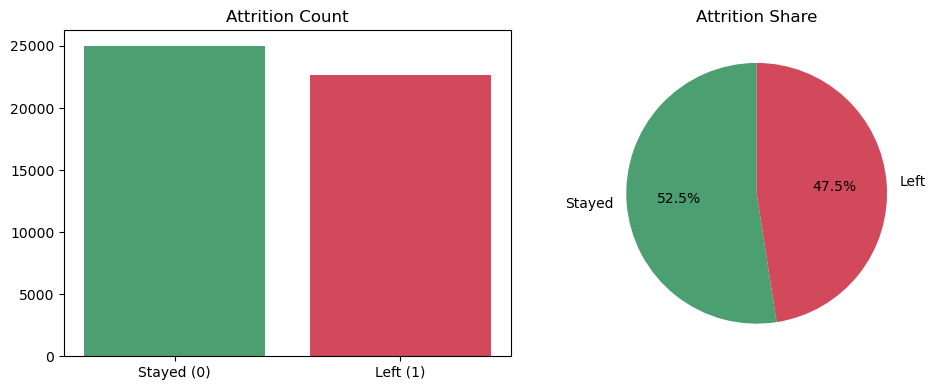

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
counts = train_eda["Attrition"].value_counts().sort_index()
ax[0].bar(["Stayed (0)", "Left (1)"], counts.values, color=["#4C9F70", "#D1495B"])
ax[0].set_title("Attrition Count")
ax[1].pie(counts.values, labels=["Stayed", "Left"], autopct="%1.1f%%",
          colors=["#4C9F70", "#D1495B"], startangle=90)
ax[1].set_title("Attrition Share")
plt.tight_layout(); plt.show()

## 4.3 Numerical features distribution

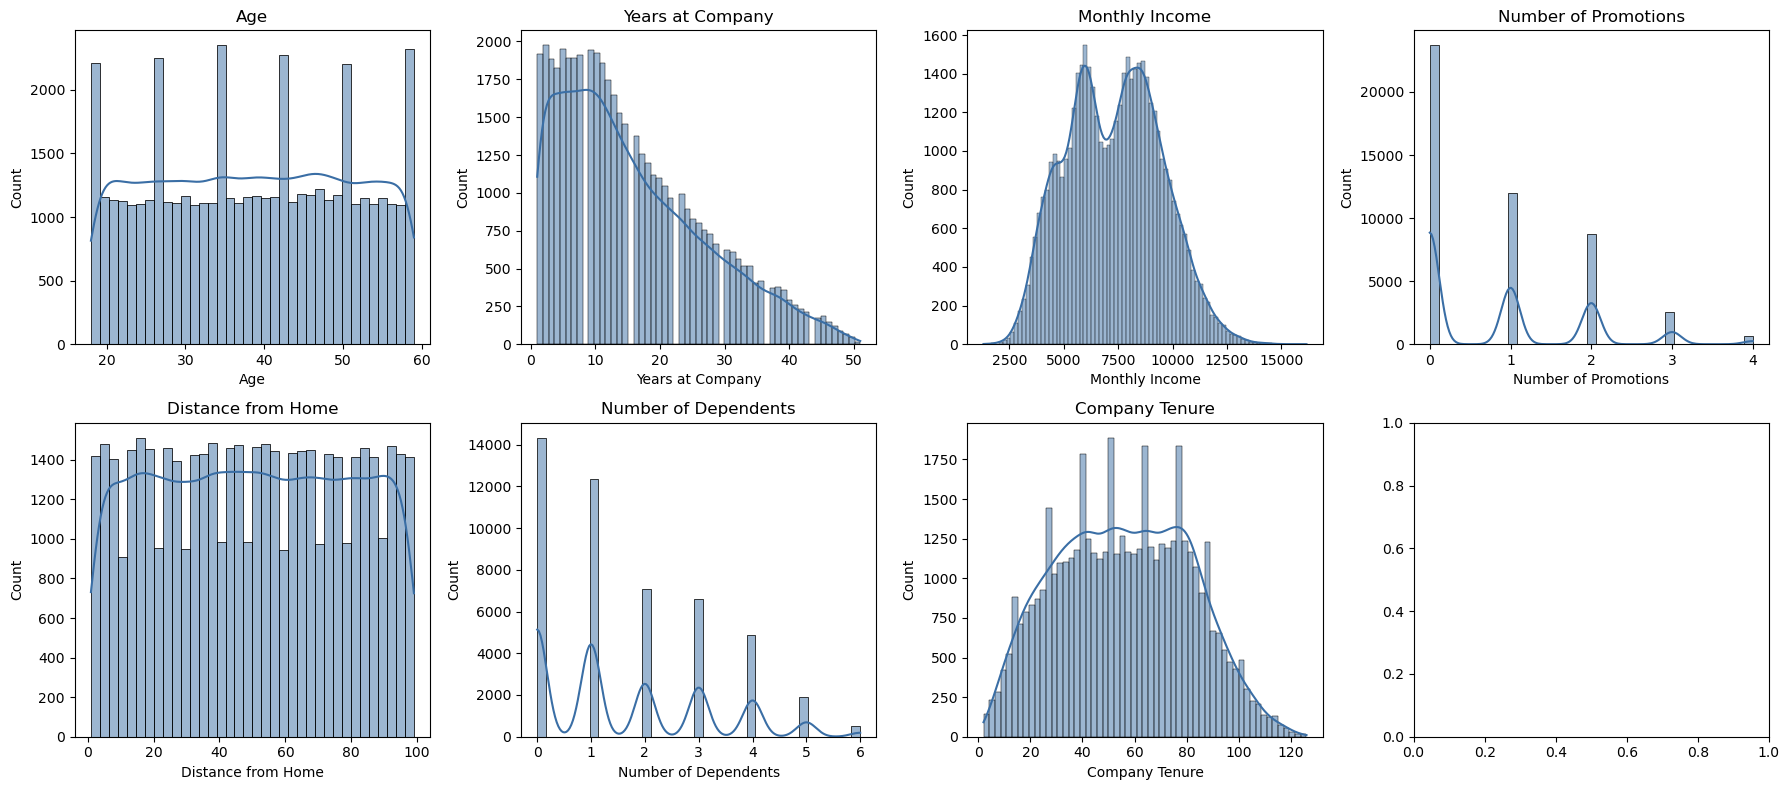

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(train_eda[col], kde = True, ax = ax, color="#3A6EA5")
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 4.4 Numerical features vs Attrition (outlier check and group difference)

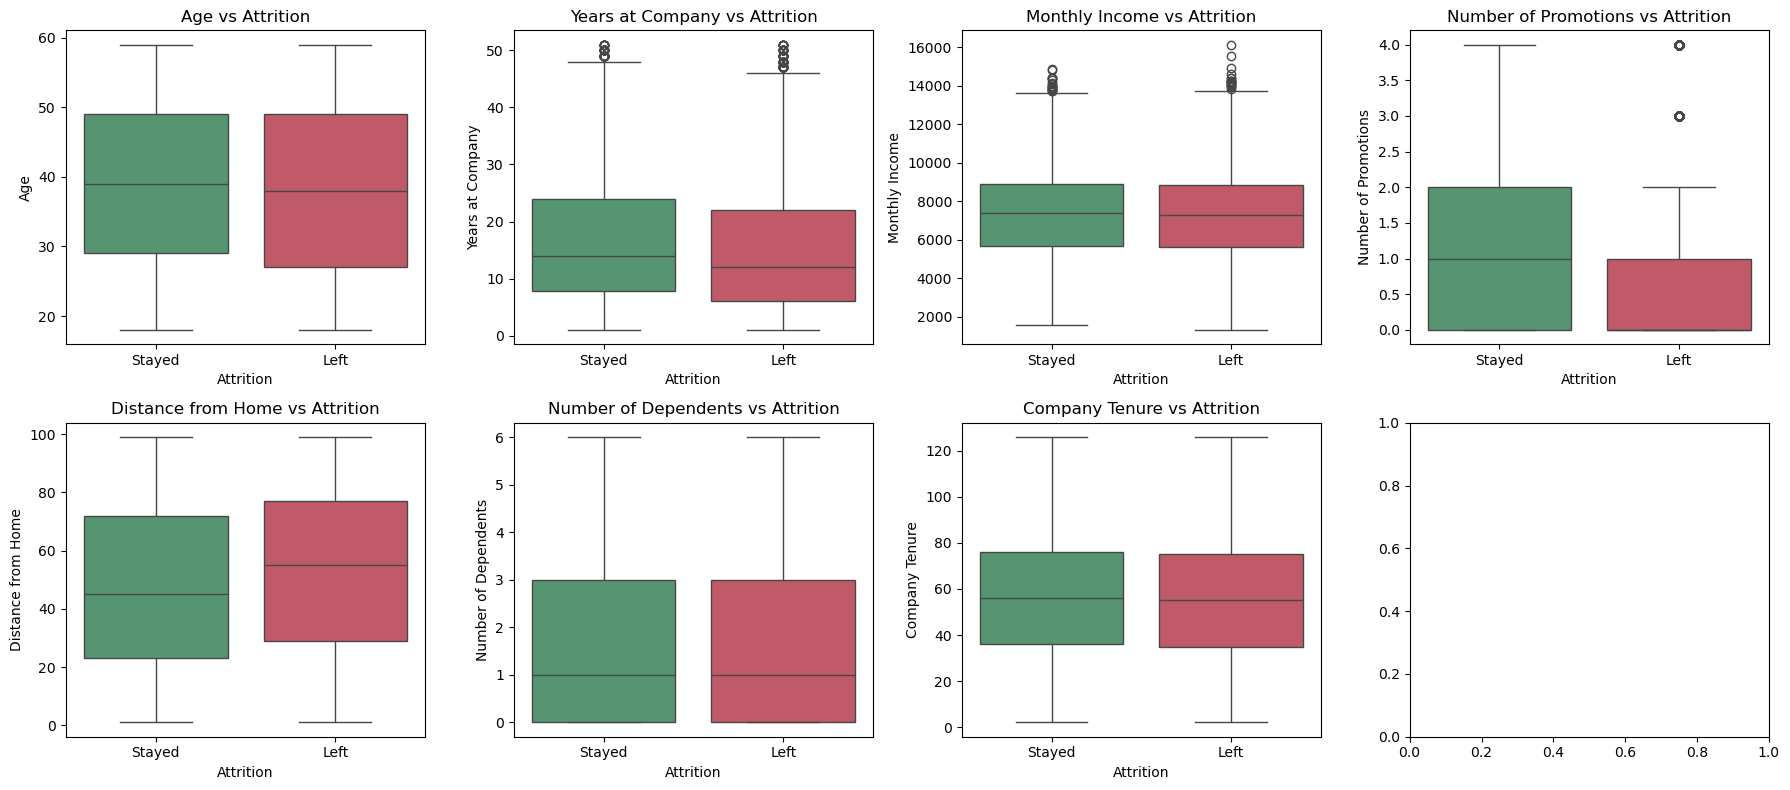

In [17]:
fig, axes = plt.subplots(2, 4, figsize = (18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x="Attrition", y=col, data=train_eda, ax=ax, palette=["#4C9F70","#D1495B"])
    ax.set_title(f"{col} vs Attrition") 
    ax.set_xticklabels(["Stayed", "Left"])
plt.tight_layout()
plt.show()

## 4.5 categorical features vs Attrition rate

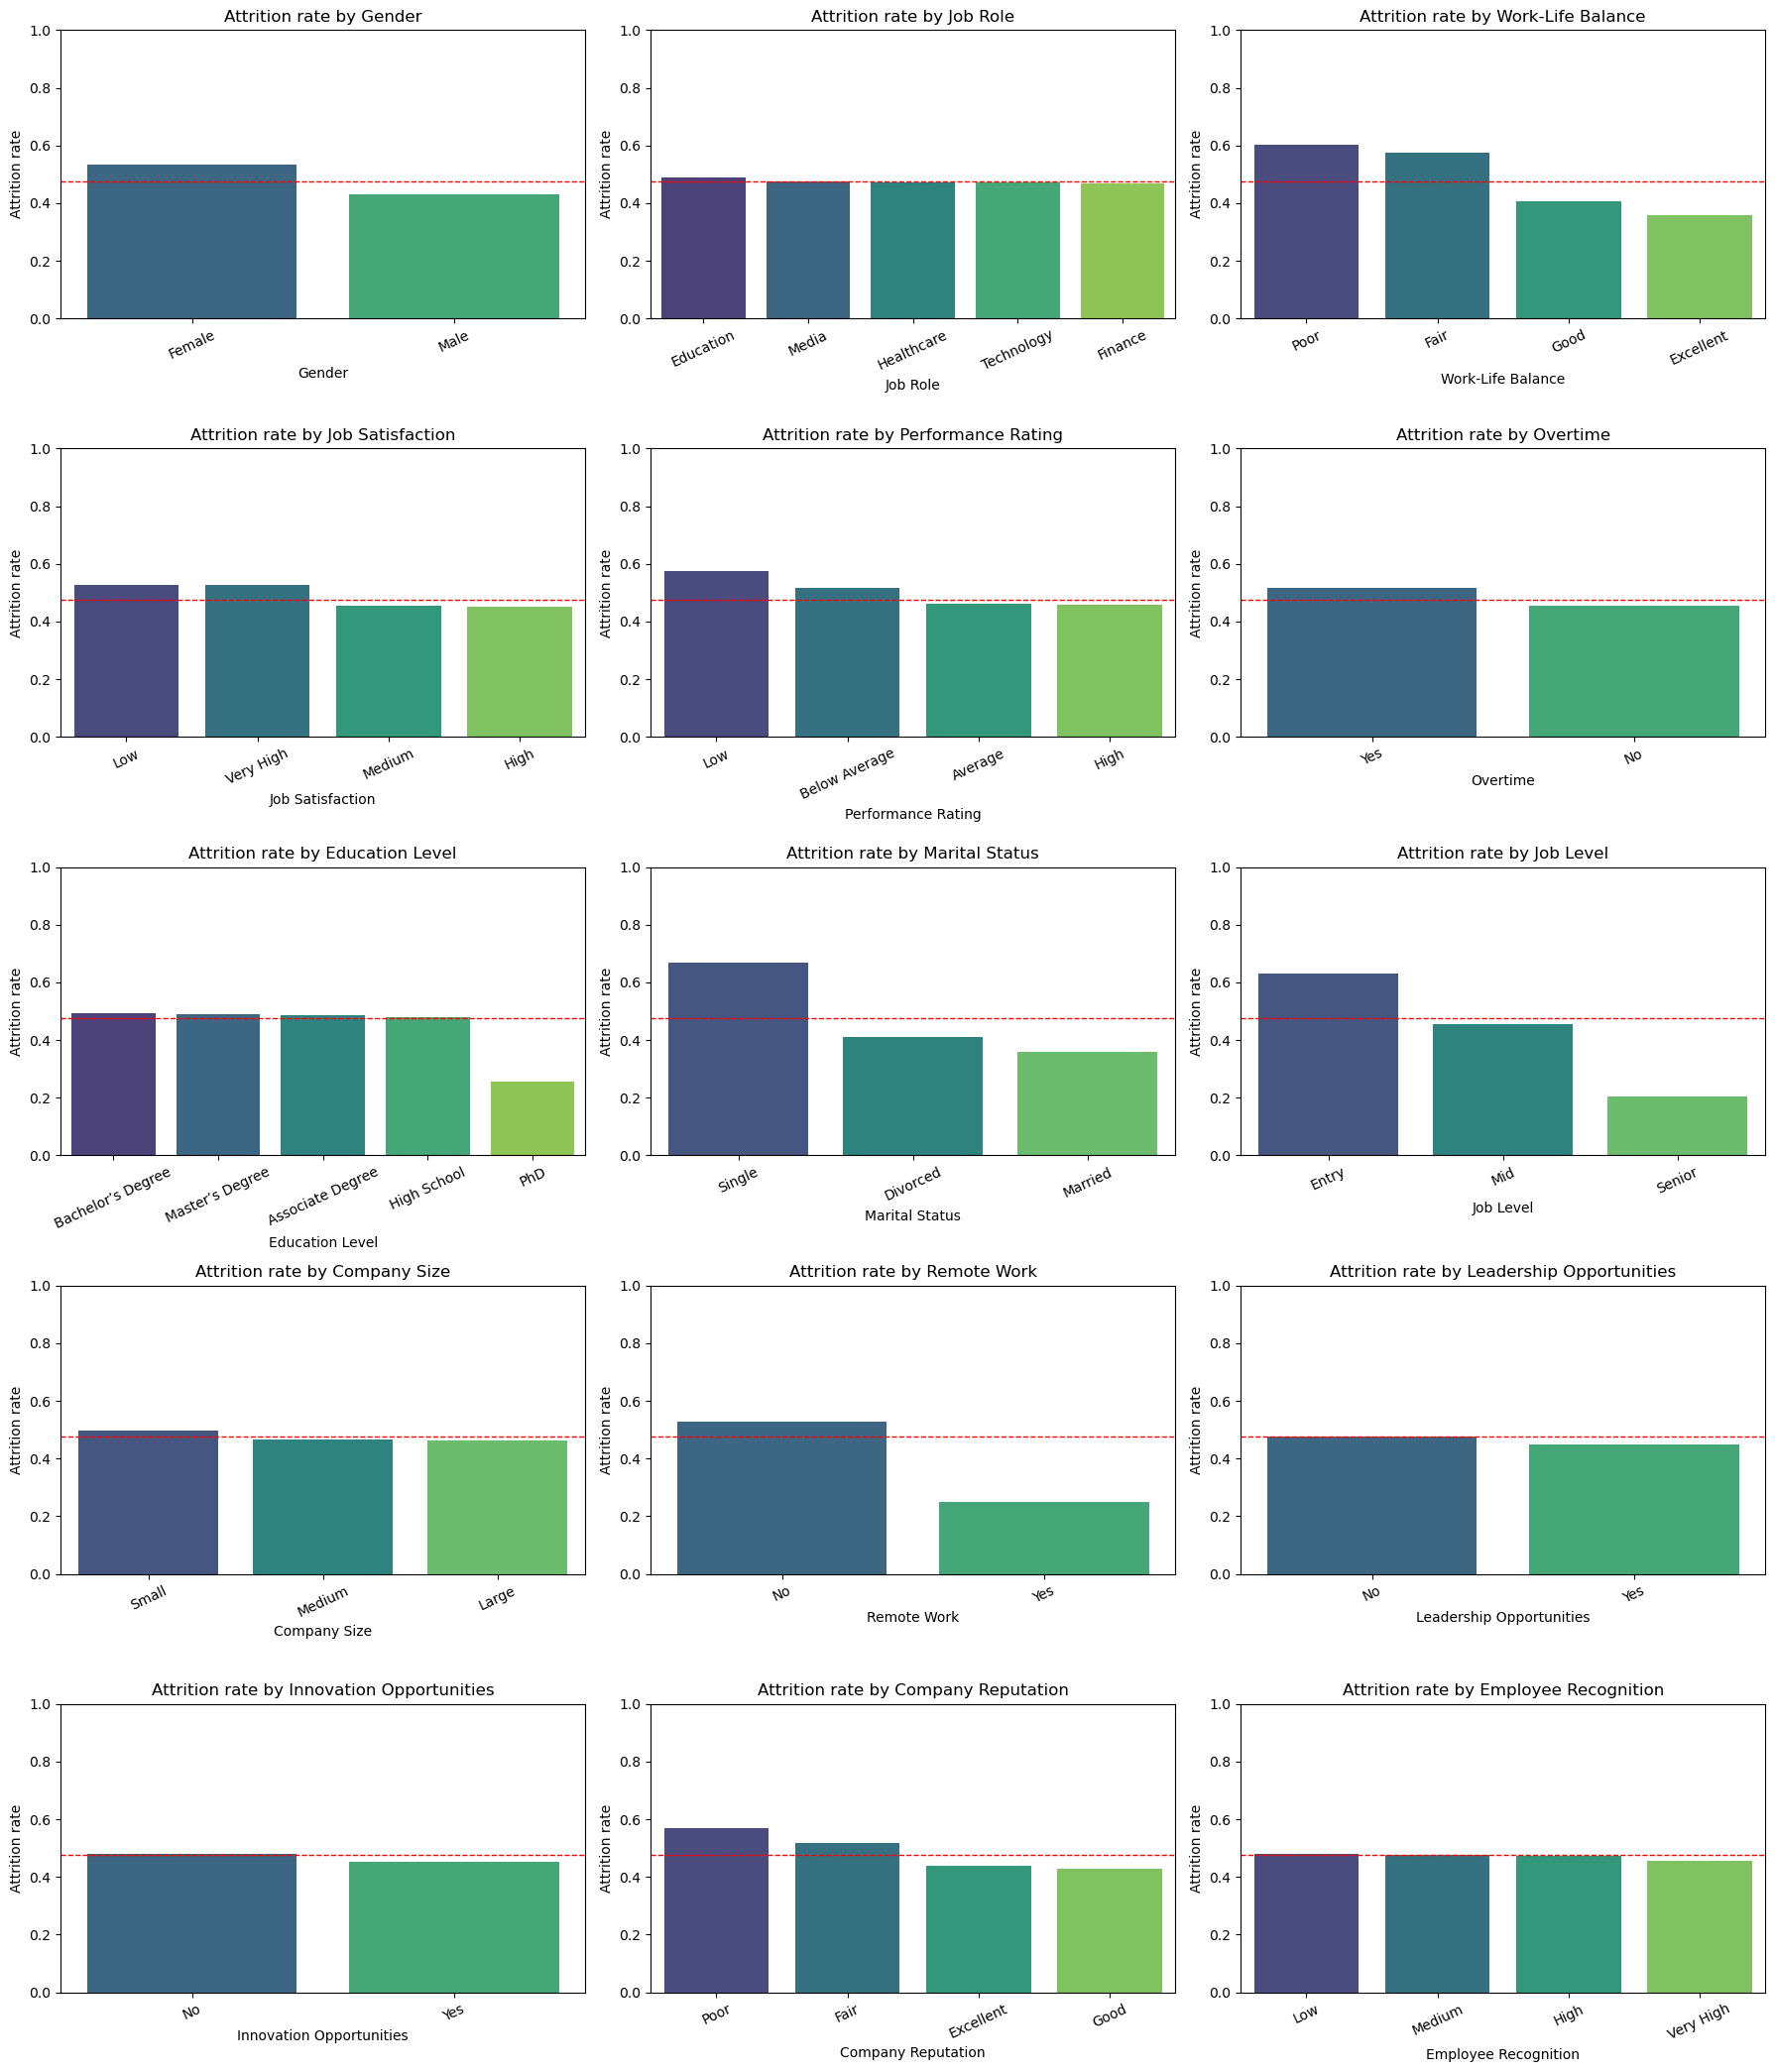

In [18]:
n = len(cat_cols)
rows = int(np.ceil(n/3))
fig, axes = plt.subplots(rows, 3, figsize=(18, 4.2 * rows))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = train_eda.groupby(col)["Attrition"].mean().sort_values(ascending = False)
    sns.barplot(x = rate.index, y = rate.values, ax = ax, palette = "viridis")
    ax.set_title(f"Attrition rate by {col}")
    ax.set_ylabel("Attrition rate")
    ax.set_ylim(0, 1)
    ax.axhline(train_eda["Attrition"].mean(), color="red", ls="--", lw=1)
    ax.tick_params(axis="x", rotation=25)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4.6 Correlation heatmap(numerical features + target)

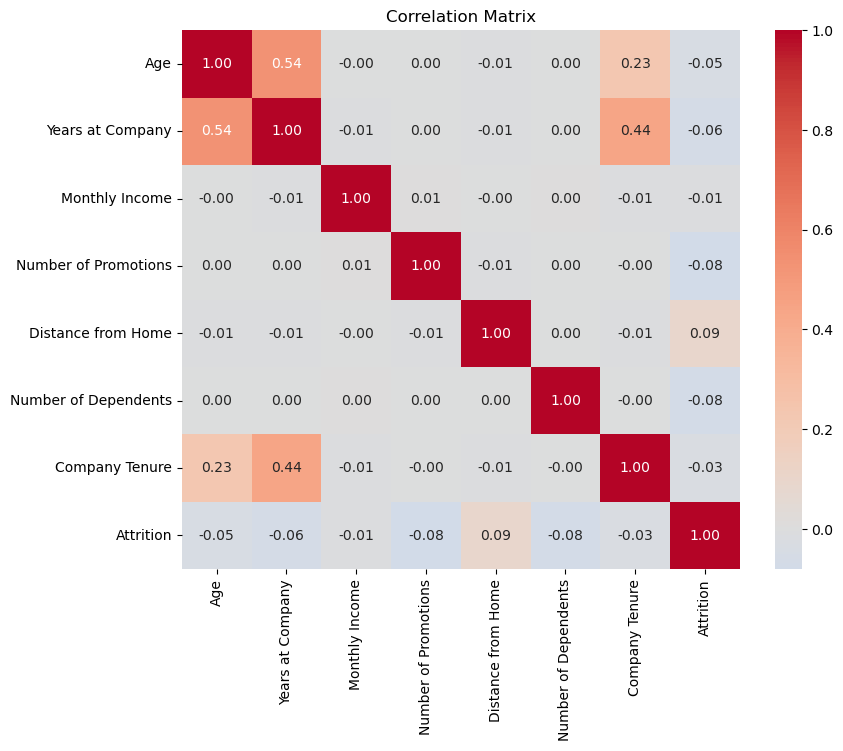

In [19]:
plt.figure(figsize=(9, 7))
sns.heatmap(train_eda[num_cols + ["Attrition"]].corr(), annot = True, fmt = ".2f", cmap="coolwarm", center = 0)
plt.title("Correlation Matrix")
plt.show()

## 4.7 Quick insights: which features differ most between leavers and stayers?

In [20]:
# Chi-square style strength: how much does attrition rate change across categories of each feature?
spread = {}
for col in cat_cols:
    r = train_eda.groupby(col)["Attrition"].mean()
    spread[col] = r.max() - r.min()
spread = pd.Series(spread).sort_values(ascending=False)
print("Spread in attrition rate across categories (bigger = more influential):")
print(spread.round(3))

Spread in attrition rate across categories (bigger = more influential):
Job Level                   0.427
Marital Status              0.307
Remote Work                 0.278
Work-Life Balance           0.245
Education Level             0.239
Company Reputation          0.141
Performance Rating          0.117
Gender                      0.103
Job Satisfaction            0.075
Overtime                    0.061
Company Size                0.035
Innovation Opportunities    0.029
Leadership Opportunities    0.029
Employee Recognition        0.023
Job Role                    0.022
dtype: float64


## 5. Data Preprocessing
The dataset has no missing values and no duplicates, so the main steps are:

* **Ordinal encoding** for categorical features that have a natural order
  (e.g. Work-Life Balance: Poor < Fair < Good < Excellent)
* **One-hot encoding** for nominal features with no order (Job Role, Marital Status, Gender, etc.)
* **Binary encoding** for Yes/No features
* **Feature engineering**: a few meaningful ratios and flags
* **Scaling** numerical features (needed for Logistic Regression and KNN; harmless for tree models)

Everything is wrapped in a **Pipeline / ColumnTransformer** that is *fitted on the training data only*
and then applied to the test data, which prevents data leakage.

In [21]:
df.columns

Index(['Employee ID', 'Age', 'Gender', 'Years at Company', 'Job Role',
       'Monthly Income', 'Work-Life Balance', 'Job Satisfaction',
       'Performance Rating', 'Number of Promotions', 'Overtime',
       'Distance from Home', 'Education Level', 'Marital Status',
       'Number of Dependents', 'Job Level', 'Company Size', 'Company Tenure',
       'Remote Work', 'Leadership Opportunities', 'Innovation Opportunities',
       'Company Reputation', 'Employee Recognition', 'Attrition'],
      dtype='object')

In [22]:
# ---------- Feature engineering (row-wise, so no leakage) ----------
def add_features(data):
    d = data.copy()
    d["Income per Year at Company"] = d["Monthly Income"]/ (d["Years at Company"] + 1)
    d["Promotions per Year"] = d["Number of Promotions"] / (d["Years at Company"] + 1)
    d["Income per Dependent"] = d["Monthly Income"] / (d["Number of Dependents"] + 1)
    d["Age at Joining"] = d["Age"] - d["Years at Company"]
    return d

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)
X_train_fe.head()

,Age,Gender,Years at Company,Job Role,Monthly Income,Work-Life Balance,Job Satisfaction,Performance Rating,Number of Promotions,Overtime,...,Company Tenure,Remote Work,Leadership Opportunities,Innovation Opportunities,Company Reputation,Employee Recognition,Income per Year at Company,Promotions per Year,Income per Dependent,Age at Joining
9111,49,Female,29,Education,4931,Good,High,Average,0,No,...,77,Yes,No,No,Good,Low,164.366667,0.000000,2465.500000,20
39671,46,Female,3,Finance,7964,Excellent,High,High,1,Yes,...,79,Yes,No,No,Poor,High,1991.000000,0.250000,1991.000000,43
38691,53,Male,28,Media,5756,Good,Low,Average,3,No,...,75,No,No,No,Good,Low,198.482759,0.103448,2878.000000,25
40509,47,Male,10,Education,3876,Good,High,Low,3,Yes,...,88,Yes,No,No,Fair,Medium,352.363636,0.272727,1938.000000,37
54406,48,Female,16,Healthcare,7601,Excellent,High,Average,3,Yes,...,71,No,No,No,Poor,Very High,447.117647,0.176471,1266.833333,32


In [23]:
df.columns

Index(['Employee ID', 'Age', 'Gender', 'Years at Company', 'Job Role',
       'Monthly Income', 'Work-Life Balance', 'Job Satisfaction',
       'Performance Rating', 'Number of Promotions', 'Overtime',
       'Distance from Home', 'Education Level', 'Marital Status',
       'Number of Dependents', 'Job Level', 'Company Size', 'Company Tenure',
       'Remote Work', 'Leadership Opportunities', 'Innovation Opportunities',
       'Company Reputation', 'Employee Recognition', 'Attrition'],
      dtype='object')

In [24]:
df["Employee Recognition"].unique()

array(['Medium', 'Low', 'High', 'Very High'], dtype=object)

In [25]:
# ---------- Column groups ----------

ordinal_map = {
    "Work-Life Balance": ["Poor", "Fair", "Good", "Excellent"],
    "Job Satisfaction": ["Low", "Medium", "High", "Very High"],
    "Performance Rating": ["Low", "Below Average", "Average", "High"],
    "Education Level": [
        "High School",
        "Associate Degree",
        "Bachelor’s Degree",  # Uses curly apostrophe ’
        "Master’s Degree",    # Uses curly apostrophe ’
        "PhD"
    ],
    "Job Level": ["Entry", "Mid", "Senior"],
    "Company Size": ["Small", "Medium", "Large"],
    "Company Reputation": ["Poor", "Fair", "Good", "Excellent"],
    "Employee Recognition": ["Low", "Medium", "High", "Very High"],
}
ordinal_cols = list(ordinal_map.keys())
binary_cols = ["Overtime", "Remote Work", "Leadership Opportunities", "Innovation Opportunities", "Gender"]
nominal_cols = ["Job Role", "Marital Status"]
numeric_cols = [c for c in X_train_fe. columns
                if c not in ordinal_cols + binary_cols + nominal_cols]

print("Numeric :", numeric_cols)
print("Ordinal :", ordinal_cols)
print("Binary :", binary_cols)
print("Nominal : ", nominal_cols)

Numeric : ['Age', 'Years at Company', 'Monthly Income', 'Number of Promotions', 'Distance from Home', 'Number of Dependents', 'Company Tenure', 'Income per Year at Company', 'Promotions per Year', 'Income per Dependent', 'Age at Joining']
Ordinal : ['Work-Life Balance', 'Job Satisfaction', 'Performance Rating', 'Education Level', 'Job Level', 'Company Size', 'Company Reputation', 'Employee Recognition']
Binary : ['Overtime', 'Remote Work', 'Leadership Opportunities', 'Innovation Opportunities', 'Gender']
Nominal :  ['Job Role', 'Marital Status']


In [26]:
preprocessor = ColumnTransformer(
    transformers = [
        ("num", StandardScaler(), numeric_cols),
        ("ord", Pipeline([
            ("enc", OrdinalEncoder(categories=[ordinal_map[c] for c in ordinal_cols])),
            ("scale", StandardScaler())]), ordinal_cols),
        ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), binary_cols),
        ("nom", OneHotEncoder(handle_unknown="ignore"), nominal_cols),
    ]
)

# Fit on Train only, transform both
X_train_proc = preprocessor.fit_transform(X_train_fe)
X_test_proc = preprocessor.transform(X_test_fe)
feature_names = preprocessor.get_feature_names_out()

print("Processed train shape:", X_train_proc.shape)
print("Processed test shape :", X_test_proc.shape)
print("Any NaN in train?    :", np.isnan(X_train_proc).any())

Processed train shape: (47678, 32)
Processed test shape : (11920, 32)
Any NaN in train?    : False


## 6. Model Selection
Several classification algorithms are compared using **5-fold stratified cross-validation on the training set only**
(the test set stays untouched until the very end). Models compared:

Logistic Regression · Decision Tree · KNN · Random Forest · Gradient Boosting · XGBoost

In [27]:
models = {
    "Logistic Regression" : LogisticRegression(max_iter = 1000, random_state = 42),
    "Decision Tree" : DecisionTreeClassifier(max_depth = 8, random_state = 42),
    "KNN" : KNeighborsClassifier(n_neighbors = 15, n_jobs = -1),
    "Random Forest" : RandomForestClassifier(n_estimators = 200, max_depth = 12, n_jobs = -1, random_state = 42),
    "Gradient Boosting" : GradientBoostingClassifier(n_estimators = 150, random_state = 42),
    "XGBoost" : XGBClassifier(n_estimators = 300, learning_rate = 0.1, max_depth = 5,
                              eval_metric = "logloss", n_jobs = -1, random_state = 42),
}

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
rows = []
for name, model in models.items():
    acc = cross_val_score(model, X_train_proc, y_train, cv = cv, scoring = "accuracy", n_jobs = -1)
    f1 = cross_val_score(model, X_train_proc, y_train, cv = cv, scoring = "f1", n_jobs = -1)
    auc = cross_val_score(model, X_train_proc, y_train, cv = cv, scoring = "roc_auc", n_jobs = -1)
    rows.append({"Model": name, "CV Accuracy": acc.mean(), "CV_F1" : f1.mean(), "CV ROC-AUC": auc.mean()})
    print(f"{name:<22} acc={acc.mean():.4f} f1={f1.mean():.4f} auc={auc.mean():.4f}")

cv_results = pd.DataFrame(rows).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
cv_results

Logistic Regression    acc=0.7426 f1=0.7272 auc=0.8294
Decision Tree          acc=0.7319 f1=0.7231 auc=0.8110
KNN                    acc=0.6972 f1=0.6853 auc=0.7664
Random Forest          acc=0.7502 f1=0.7330 auc=0.8392
Gradient Boosting      acc=0.7576 f1=0.7442 auc=0.8498
XGBoost                acc=0.7547 f1=0.7418 auc=0.8443


,Model,CV Accuracy,CV_F1,CV ROC-AUC
0,Gradient Boosting,0.757603,0.744220,0.849837
1,XGBoost,0.754709,0.741849,0.844284
2,Random Forest,0.750241,0.732981,0.839216
3,Logistic Regression,0.742565,0.727201,0.829430
4,Decision Tree,0.731910,0.723094,0.810966
5,KNN,0.697177,0.685291,0.766416


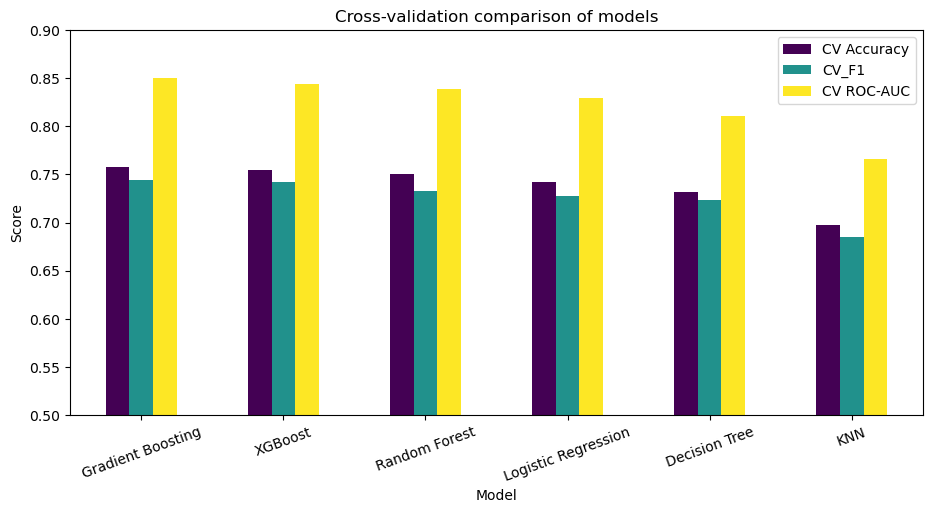

Best model by CV ROC-AUC: Gradient Boosting


In [28]:
cv_results.set_index("Model")[["CV Accuracy", "CV_F1", "CV ROC-AUC"]].plot(
    kind = "bar", figsize = (11, 5), ylim = (0.5, 0.9), colormap = "viridis")
plt.title("Cross-validation comparison of models")
plt.xticks(rotation = 20)
plt.ylabel("Score")
plt.show()

best_name = cv_results.loc[0, "Model"]
print("Best model by CV ROC-AUC:", best_name)

## 7. Hyperparameter Tuning

The best-performing family is tuned with `GridSearchCV` (still using only the training data).
A smaller grid is used so it runs in reasonable time on a normal laptop.

In [29]:
param_grids = {
    "XGBoost": (XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=42),
                {"n_estimators": [200, 400], "max_depth": [3, 5], "learning_rate": [0.05, 0.1],
                 "subsample": [0.8, 1.0]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
                {"n_estimators": [100, 200], "max_depth": [3, 4], "learning_rate": [0.05, 0.1]}),
    "Random Forest": (RandomForestClassifier(n_jobs=-1, random_state=42),
                {"n_estimators": [200, 400], "max_depth": [10, 15, None], "min_samples_leaf": [1, 3]}),
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=42),
                {"C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42),
                {"max_depth": [4, 6, 8, 12], "min_samples_leaf": [1, 5, 20]}),
    "KNN": (KNeighborsClassifier(n_jobs=-1), {"n_neighbors": [5, 15, 25, 35]}),
}

estimator, grid = param_grids[best_name]
search = GridSearchCV(estimator, grid, cv=3, scoring="roc_auc", n_jobs=-1, verbose=1)
search.fit(X_train_proc, y_train)

print("Best params :", search.best_params_)
print("Best CV AUC :", round(search.best_score_, 4))
best_model = search.best_estimator_

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best params : {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best CV AUC : 0.8493


## 8. Final Training and Testing

The tuned model (already fitted on the full training set by `GridSearchCV`) is now evaluated on the **unseen 20% test set**.

In [30]:
y_pred  = best_model.predict(X_test_proc)
y_proba = best_model.predict_proba(X_test_proc)[:,1]

print(f"Model : {best_name}")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC : {roc_auc_score(y_test, y_proba):.4f}")
print()
print(classification_report(y_test, y_pred, target_names = ["Stayed", "Left"]))

Model : Gradient Boosting
Accuracy : 0.7564
Precision : 0.7452
Recall : 0.7410
F1-score : 0.7431
ROC-AUC : 0.8505

              precision    recall  f1-score   support

      Stayed       0.77      0.77      0.77      6252
        Left       0.75      0.74      0.74      5668

    accuracy                           0.76     11920
   macro avg       0.76      0.76      0.76     11920
weighted avg       0.76      0.76      0.76     11920



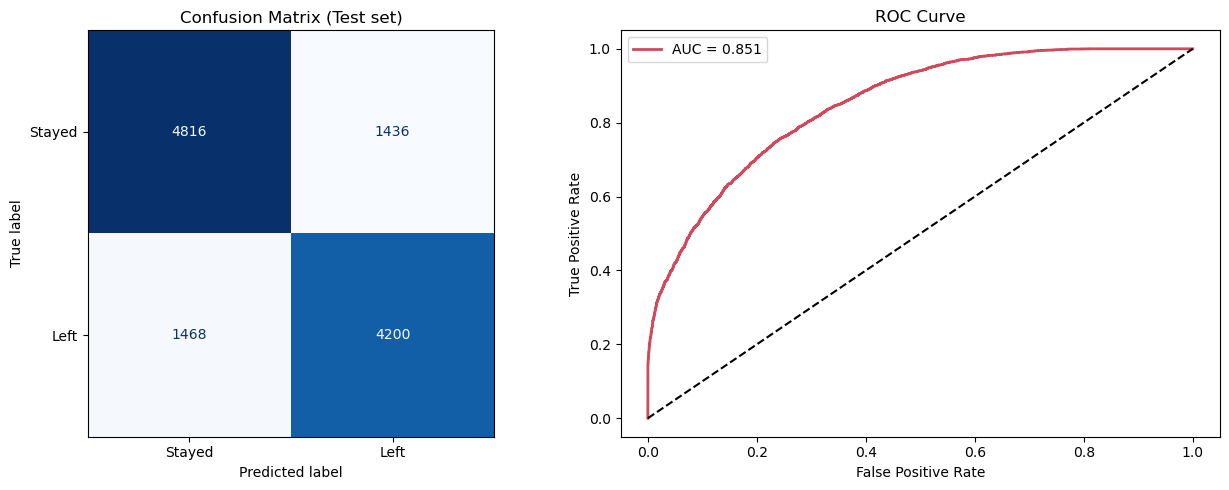

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Stayed", "Left"]).plot(
    ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix (Test set)")

fpr, tpr, _ = roc_curve(y_test, y_proba)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_proba):.3f}", color="#D1495B", lw=2)
ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve"); ax[1].legend()
plt.tight_layout(); plt.show()

## Train vs Test performance (overfitting check)

In [32]:
train_acc = accuracy_score(y_train, best_model.predict(X_train_proc))
test_acc = accuracy_score(y_test, y_pred)
print(f"Train accuracy : {train_acc:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print(f"Gap : {train_acc - test_acc:.4f} (a small gap means the model generalises well)")

Train accuracy : 0.7667
Test accuracy: 0.7564
Gap : 0.0103 (a small gap means the model generalises well)


## Feature importance: what drives attrition?

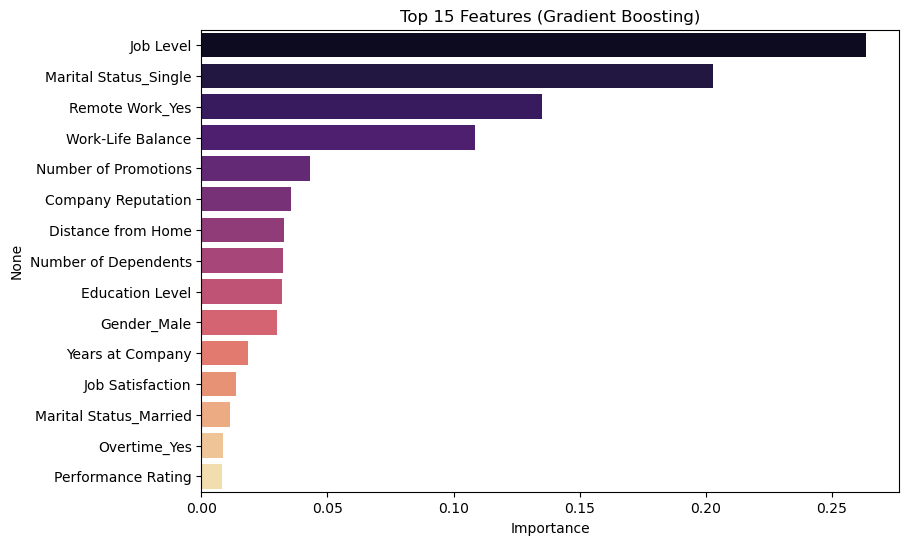

In [33]:
if hasattr(best_model, "feature_importances_"):
    imp = pd.Series(best_model.feature_importances_, index=feature_names)
elif hasattr(best_model, "coef_"):
    imp = pd.Series(np.abs(best_model.coef_[0]), index=feature_names)
else:
    imp = None

if imp is not None:
    imp = imp.sort_values(ascending=False).head(15)
    imp.index = [i.split("__", 1)[-1] for i in imp.index]
    plt.figure(figsize=(9, 6))
    sns.barplot(x=imp.values, y=imp.index, palette="magma")
    plt.title(f"Top 15 Features ({best_name})")
    plt.xlabel("Importance"); plt.show()
else:
    print("Feature importance is not available for this model type.")

## 9. Model Predictions

Predictions on the test set, shown next to the actual outcome, with the model's probability of leaving.

In [34]:
predictions = X_test.copy()
predictions["Actual"] = y_test.map({1: "Left", 0: "Stayed"}).values
predictions["Predicted"] = pd.Series(y_pred).map({1: "Left", 0: "Stayed"}).values
predictions["Probability of Leaving"] = y_proba.round(3)
predictions["Correct?"] = np.where(predictions["Actual"] == predictions["Predicted"], "Yes", "No")

predictions[["Age", "Job Role", "Monthly Income", "Overtime", "Work-Life Balance", 
             "Job Satisfaction", "Actual", "Predicted", "Probability of Leaving", "Correct?"]].head(20)

,Age,Job Role,Monthly Income,Overtime,Work-Life Balance,Job Satisfaction,Actual,Predicted,Probability of Leaving,Correct?
51025,45,Finance,9950,Yes,Fair,High,Stayed,Stayed,0.282,Yes
39466,56,Healthcare,7451,Yes,Good,High,Stayed,Stayed,0.348,Yes
40843,22,Education,4431,No,Fair,High,Stayed,Stayed,0.148,Yes
48712,40,Technology,9943,No,Good,High,Stayed,Stayed,0.048,Yes
56753,45,Finance,10787,No,Excellent,Medium,Left,Stayed,0.437,No
18294,55,Finance,6875,No,Fair,High,Left,Left,0.570,Yes
51939,52,Finance,12948,No,Excellent,High,Stayed,Stayed,0.388,Yes
44628,48,Education,4536,Yes,Good,High,Stayed,Stayed,0.028,Yes
9170,27,Education,5093,No,Excellent,Low,Left,Left,0.510,Yes
21402,38,Media,6663,No,Good,High,Left,Left,0.830,Yes


In [35]:
print("Predicated distribution on test set:")
print(predictions["Predicted"].value_counts())
print(f"\nCorrect predictions: {(predictions["Correct?"] == "Yes").sum()} of {len(predictions)}")

# Save all predictions to CSV
predictions.to_csv("Employee_attrition_predictions.csv", index = False)
print("\nSaved: employee_attrition_predictions.csv")

Predicated distribution on test set:
Predicted
Stayed    6284
Left      5636
Name: count, dtype: int64

Correct predictions: 9016 of 11920

Saved: employee_attrition_predictions.csv


## Predicting for a brand-new employee

In [36]:
new_employee = pd.DataFrame([{
    "Age" : 29,
    "Gender" : "Female",
    "Years at Company": 3,
    "Job Role" : "Technology",
    "Monthly Income" : 4500, 
    "Work-Life Balance" : "Poor",
    "Job Satisfaction" : "Low",
    "Performance Rating" : "Average",
    "Number of Promotions" : 0,
    "Overtime" : "Yes",
    "Distance from Home": 60, 
    "Education Level" : "Bachelor’s Degree",
    "Marital Status" : "Single",
    "Number of Dependents" : 0,
    "Job Level" : "Entry",
    "Company Size" : "Medium",
    "Company Tenure" : 30, 
    "Remote Work" : "No", 
    "Leadership Opportunities" : "No",
    "Innovation Opportunities" : "No", 
    "Company Reputation" : "Fair",
    "Employee Recognition" : "Low",
}])

x_new = preprocessor.transform(add_features(new_employee))
prob = best_model.predict_proba(x_new)[0, 1]
print(f"Probability of Leaving: {prob:.1%}")
print("Prediction:", "LEAVE" if prob >= 0.5 else "STAY")

Probability of Leaving: 98.9%
Prediction: LEAVE


## 10. Conclusion
* The dataset was split **80/20 (stratified)** before any analysis, so the test set is a fair, unseen evaluation.
* EDA and preprocessing were learned from training data only (no data leakage).
* Six algorithms were compared with 5-fold cross-validation; the best one was tuned with GridSearchCV.
* Final performance on the test set is reported above (Accuracy, Precision, Recall, F1, ROC-AUC).
* Feature-importance analysis shows which HR factors matter most for attrition, which HR teams can use to design retention actions
  (e.g. work-life balance, overtime, job level, satisfaction).

**Possible improvements:** try class-weight tuning, SMOTE, SHAP explanations, or additional features if more data becomes available.